# **Day 100: Writing Good Python Code, and What to Learn Next**

We have reached **Day 100**! Today we look at how to write **clean Python code**, look back at the journey, and plan what to learn next.

## **PEP 8: The Python Style Guide**
**PEP 8** is the official guide for writing neat Python code. The most important rules:
- Use **4 spaces** for indentation.
- **snake_case** for variables and functions (`district_name`), **PascalCase** for classes (`SatelliteImage`), **UPPER_CASE** for constants (`MAX_CLOUD`).
- Keep lines short (about 79 to 99 characters).
- Put two blank lines between functions and classes.
- Put all imports at the top of the file.

Tools like **black** and **ruff** can format and check code automatically:
```bash
pip install ruff
ruff check .
ruff format .
```

## **Pythonic Code: Before and After**
**"Pythonic"** means writing code in the simple, clear way that Python is designed for.

In [1]:
cities = ["Kolkata", "Howrah", "Siliguri", "Durgapur"]

# Not Pythonic: looping with an index number
for i in range(len(cities)):
    print(i, cities[i], end="; ")
print()

# Pythonic: enumerate
for i, city in enumerate(cities):
    print(i, city, end="; ")

0 Kolkata; 1 Howrah; 2 Siliguri; 3 Durgapur; 
0 Kolkata; 1 Howrah; 2 Siliguri; 3 Durgapur; 

In [2]:
# Not Pythonic
long_names = []
for c in cities:
    if len(c) > 6:
        long_names.append(c.upper())

# Pythonic: list comprehension
long_names_2 = [c.upper() for c in cities if len(c) > 6]
print(long_names == long_names_2, long_names_2)

True ['KOLKATA', 'SILIGURI', 'DURGAPUR']


In [3]:
# Not Pythonic: checking length to see if a list is empty
items = []
if len(items) == 0:
    print("Empty (long way)")

# Pythonic
if not items:
    print("Empty (Pythonic way)")

Empty (long way)
Empty (Pythonic way)


In [4]:
# Counting: the long way vs Counter
from collections import Counter
words = "ndvi ndwi ndvi ndbi ndvi".split()

counts = {}
for w in words:
    if w in counts:
        counts[w] += 1
    else:
        counts[w] = 1

print(counts == Counter(words), Counter(words).most_common(1))

True [('ndvi', 3)]


In [5]:
# Swapping, chained comparison, unpacking and any()
a, b = 1, 2
a, b = b, a
ndvi = 0.45
print(0.2 <= ndvi < 0.5)
first, *_, last = cities
print(first, last, any(c.startswith("S") for c in cities))

True
Kolkata Durgapur True


## **The Zen of Python**
Python has a small poem of good coding advice built into it.

In [6]:
import this

The Zen of Python, by Tim Peters

Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better than nested.
Sparse is better than dense.
Readability counts.
Special cases aren't special enough to break the rules.
Although practicality beats purity.
Errors should never pass silently.
Unless explicitly silenced.
In the face of ambiguity, refuse the temptation to guess.
There should be one-- and preferably only one --obvious way to do it.
Although that way may not be obvious at first unless you're Dutch.
Now is better than never.
Although never is often better than *right* now.
If the implementation is hard to explain, it's a bad idea.
If the implementation is easy to explain, it may be a good idea.
Namespaces are one honking great idea -- let's do more of those!


## **Looking Back: Numbers About This Course**
This notebook can read **all the other notebooks** (a notebook is just a JSON file!) and count some things about them.

In [7]:
import json, re
from pathlib import Path

notebooks = sorted(Path("..").glob("*/Day_*.ipynb"))
print(len(notebooks), "notebooks found")

code_cells = markdown_cells = code_lines = 0
imports = Counter()
places = Counter()
rs_words = Counter()
PLACES = ["Kolkata", "Howrah", "Siliguri", "Darjeeling", "Midnapore", "Kharagpur", "Digha", "Sundarbans",
          "Purulia", "Bankura", "Durgapur", "Ghatal", "Kalimpong", "Jalpaiguri", "Malda", "Asansol"]
RS_WORDS = ["NDVI", "NDWI", "Landsat", "Sentinel", "pixel", "band", "raster", "GeoJSON", "UTM", "DEM"]

for nb_path in notebooks:
    nb = json.loads(nb_path.read_text(encoding="utf-8"))
    for cell in nb["cells"]:
        source = "".join(cell["source"])
        if cell["cell_type"] == "code":
            code_cells += 1
            code_lines += sum(1 for line in source.splitlines() if line.strip() and not line.strip().startswith("#"))
            for module in re.findall(r"^\s*(?:from|import)\s+([A-Za-z_]\w*)", source, flags=re.M):
                imports[module] += 1
        else:
            markdown_cells += 1
        for p in PLACES:
            places[p] += source.count(p)
        for w in RS_WORDS:
            rs_words[w] += len(re.findall(rf"\b{w}", source, flags=re.I))

print(f"Code cells: {code_cells}, Markdown cells: {markdown_cells}, Lines of code: about {code_lines:,}")
print("Most imported modules:", imports.most_common(8))

100 notebooks found


Code cells: 944, Markdown cells: 965, Lines of code: about 7,291
Most imported modules: [('matplotlib', 19), ('math', 17), ('numpy', 17), ('sys', 9), ('random', 9), ('collections', 9), ('time', 8), ('pandas', 8)]


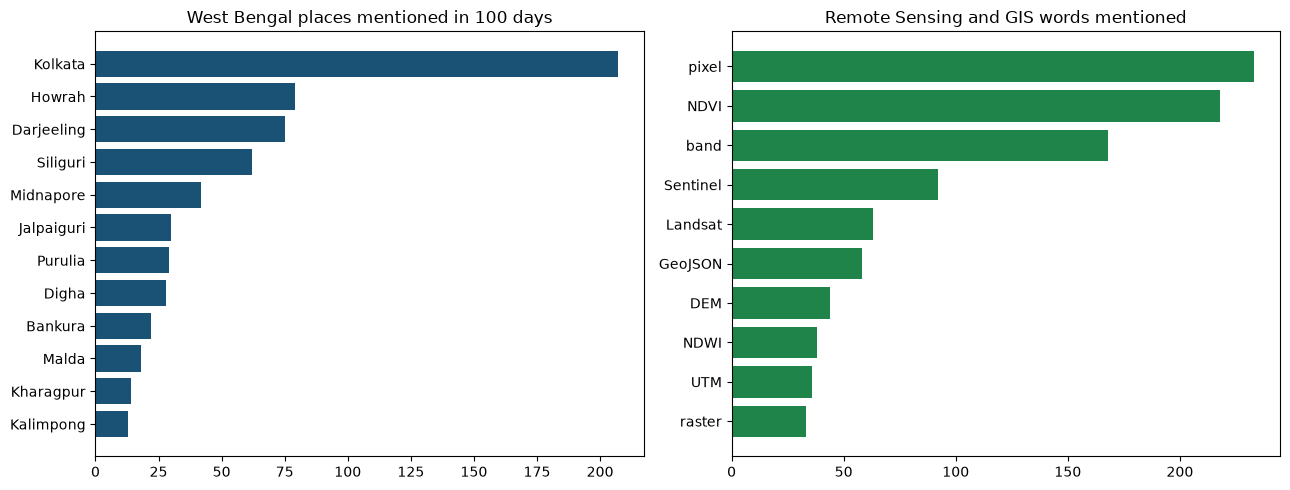

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

top_places = places.most_common(12)[::-1]
axes[0].barh([p for p, _ in top_places], [n for _, n in top_places], color="#1a5276")
axes[0].set_title("West Bengal places mentioned in 100 days")

top_rs = rs_words.most_common()[::-1]
axes[1].barh([w for w, _ in top_rs], [n for _, n in top_rs], color="#1e8449")
axes[1].set_title("Remote Sensing and GIS words mentioned")

plt.tight_layout()
plt.show()

In [9]:
phase_counts = Counter(p.parent.name for p in notebooks)
for name, n in sorted(phase_counts.items()):
    print(f"{name:<30}{n:>3} days")

01_Basics                      20 days
02_Functions_Modules_Files     20 days
03_Object_Oriented_Programming 20 days
04_Advanced_Python             20 days
05_Libraries_GIS_and_Projects  20 days


## **What These 100 Days Covered**
| Days | Phase | Main topics |
|---|---|---|
| 1 - 20 | Basics | print, variables, strings, conditions, loops, lists, tuples, sets, dictionaries |
| 21 - 40 | Functions and Files | functions, comprehensions, recursion, modules, files, CSV, JSON / GeoJSON, errors, logging |
| 41 - 60 | OOP | classes, the four pillars of OOP, magic methods, dataclasses, enums, iterators, generators, decorators |
| 61 - 80 | Advanced | type hints, regex, testing, threads, processes, asyncio, SQLite, web APIs, scraping, speed, memory |
| 81 - 100 | Libraries and GIS | NumPy, Pandas, Matplotlib, projections, vector and raster data, classification, flood mapping, Flask, pipelines |

## **Tips for Anyone Starting at Day 1**
1. **Type the code yourself.** Reading alone is not enough.
2. **Errors are normal.** Read the last line of the error message first.
3. **Build small projects** about things you care about (for us: metro, mishti, pujo, and satellite images of West Bengal).
4. **A little every day** is better than a lot once a week.
5. **Learn to search:** the Python documentation, Stack Overflow, and other people's code.

## **What to Learn Next (for Remote Sensing and GIS)**
1. **GeoPandas, Rasterio, Shapely, PyProj** in depth (Day 99)
2. **Google Earth Engine** with Python (`geemap`) for large-area analysis
3. **Machine learning** for classification: scikit-learn (Random Forest, SVM), then **deep learning** (U-Net for image segmentation)
4. **PyQGIS**: automating QGIS with Python
5. **SAR** (radar) data processing with Sentinel-1
6. **Web GIS**: Flask/FastAPI with PostGIS and Leaflet

**100 days completed!**